# 🌊 BASELINE: Grid 16px Flood Susceptibility (Topography Only)
Binary classifier using only terrain features. No SAR, no distillation.


In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

PERM_WATER_THRESH = "20"
BASE_DIR = "/content/drive/MyDrive/new_data_flood"
GRID_DIR = os.path.join(BASE_DIR, "ML/grid_area")

PATHS = {
    "train": os.path.join(GRID_DIR, f"ML_train/train_grid_16px_permWater_thresh{PERM_WATER_THRESH}.csv"),
    "valid": os.path.join(GRID_DIR, f"ML_valid/valid_grid_16px_permWater_thresh{PERM_WATER_THRESH}.csv"),
    "test": os.path.join(GRID_DIR, f"ML_test/test_grid_16px_permWater_thresh{PERM_WATER_THRESH}.csv")
}



Mounted at /content/drive


In [3]:
import gc

print("📥 Loading Datasets and Downcasting to save RAM...")

def load_and_downcast(path):
    df = pd.read_csv(path)
    # Downcast 64-bit floats to 32-bit to cut memory usage in half
    float_cols = df.select_dtypes(include=['float64']).columns
    df[float_cols] = df[float_cols].astype(np.float32)
    return df

df_train = load_and_downcast(PATHS["train"])
df_valid = load_and_downcast(PATHS["valid"])
df_test = load_and_downcast(PATHS["test"])

print(f"Train: {df_train.shape} | Valid: {df_valid.shape} | Test: {df_test.shape}")


📥 Loading Datasets and Downcasting to save RAM...
Train: (4512704, 41) | Valid: (3437056, 41) | Test: (3330432, 41)


In [4]:
SEVERE_FLOOD_THRESHOLD = 0.15 # 18% to organically balance 50/50

print("🌪️ Filtering for Extreme Disaster Scenarios (Removing dry tiles)...")
def filter_severe_floods(df):
    if 'sample_id' not in df.columns or 'label' not in df.columns:
        return df

    # Calculate the total fraction of flooded grids for each image (sample_id)
    sample_flood_stats = df.groupby('sample_id')['label'].mean()

    # Identify images that have significant flooding
    severe_samples = sample_flood_stats[sample_flood_stats >= SEVERE_FLOOD_THRESHOLD].index

    # Keep only the rows belonging to those severe flood images
    return df[df['sample_id'].isin(severe_samples)].copy()

df_train = filter_severe_floods(df_train)
df_valid = filter_severe_floods(df_valid)
df_test = filter_severe_floods(df_test)

# 🚀 NEW: Combine Train and Valid, then borrow 50% of Test sequentially to preserve regional isolation!
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

if 'sample_id' in df_train.columns:
    print("⚖️ Re-balancing dataset sequentially to preserve regional isolation...")

    # 1. Borrow exactly half of the Test regions for the training pool
    test_samples = df_test['sample_id'].unique()
    test_samples = np.sort(test_samples) # Sort to keep geographic regions grouped!
    split_test_idx = len(test_samples) // 2

    borrowed_samples = test_samples[:split_test_idx]
    strict_test_samples = test_samples[split_test_idx:]

    df_borrowed = df_test[df_test['sample_id'].isin(borrowed_samples)].copy()
    df_test = df_test[df_test['sample_id'].isin(strict_test_samples)].copy()

    # 2. Combine Original Train, Original Valid, and Borrowed Test into a massive pool
    df_combined = pd.concat([df_train, df_valid, df_borrowed], ignore_index=True)

    # 3. Sequentially split the massive pool into 85% Train / 15% Valid
    pool_samples = np.sort(df_combined['sample_id'].unique())
    split_val_idx = int(len(pool_samples) * 0.85)

    train_samples = pool_samples[:split_val_idx]
    valid_samples = pool_samples[split_val_idx:]

    df_train = df_combined[df_combined['sample_id'].isin(train_samples)].copy()
    df_valid = df_combined[df_combined['sample_id'].isin(valid_samples)].copy()

print(f"After Strict Split - Train: {df_train.shape} | Valid: {df_valid.shape} | Test: {df_test.shape}")

# 🚀 NEW: Add Pseudo-GNN Spatial Context (Relative Normalization)
print("🌍 Computing Pseudo-GNN Spatial Context features...")
def add_spatial_context(df):
    if 'sample_id' not in df.columns or 'dem_mean' not in df.columns:
        return df

    # Calculate tile-level minimums and maximums
    tile_stats = df.groupby('sample_id').agg(
        tile_dem_min=('dem_mean', 'min'),
        tile_twi_max=('twi_mean', 'max')
    ).reset_index()

    # Merge back into original dataframe
    df = df.merge(tile_stats, on='sample_id', how='left')

    # Create relative features
    df['relative_elevation'] = df['dem_mean'] - df['tile_dem_min']
    df['relative_twi'] = df['twi_mean'] / (df['tile_twi_max'] + 1e-6)

    # Drop the temporary aggregate columns so we don't bloat memory
    df = df.drop(columns=['tile_dem_min', 'tile_twi_max'])
    return df

df_train = add_spatial_context(df_train)
df_valid = add_spatial_context(df_valid)
df_test = add_spatial_context(df_test)

# 🚀 NEW: Vectorized Local GNN Convolution (3x3 Edge Detection)
print("🧠 Computing Local GNN Convolutions (3x3 spatial matrices)...")
def add_local_convolution(df):
    if 'sample_id' not in df.columns or 'grid_id' not in df.columns or 'dem_mean' not in df.columns:
        return df

    df = df.copy()

    # Create neighbor grid_ids mapping
    df['left_gid'] = np.where(df['grid_id'] % 14 != 0, df['grid_id'] - 1, np.nan)
    df['right_gid'] = np.where(df['grid_id'] % 14 != 13, df['grid_id'] + 1, np.nan)
    df['top_gid'] = np.where(df['grid_id'] >= 14, df['grid_id'] - 14, np.nan)
    df['bottom_gid'] = np.where(df['grid_id'] < 196 - 14, df['grid_id'] + 14, np.nan)

    # Fast lookup table for values
    # Add perm_water if it exists
    cols_to_lookup = ['sample_id', 'grid_id', 'dem_mean', 'twi_mean', 'slope_mean']
    if 'perm_water_fraction' in df.columns: cols_to_lookup.append('perm_water_fraction')
    elif 'perm_water_percentage' in df.columns: cols_to_lookup.append('perm_water_percentage')

    lookup = df[cols_to_lookup]

    # Merge for each direction
    for direction in ['left', 'right', 'top', 'bottom']:
        rename_dict = {'grid_id': f'{direction}_gid',
                       'dem_mean': f'{direction}_dem',
                       'twi_mean': f'{direction}_twi',
                       'slope_mean': f'{direction}_slope'}
        if 'perm_water_fraction' in df.columns: rename_dict['perm_water_fraction'] = f'{direction}_perm'
        elif 'perm_water_percentage' in df.columns: rename_dict['perm_water_percentage'] = f'{direction}_perm'

        df = df.merge(lookup.rename(columns=rename_dict), on=['sample_id', f'{direction}_gid'], how='left')

    # Calculate local mean across the 4 physical neighbors
    df['neighbor_dem_mean'] = df[['left_dem', 'right_dem', 'top_dem', 'bottom_dem']].mean(axis=1)
    df['neighbor_twi_mean'] = df[['left_twi', 'right_twi', 'top_twi', 'bottom_twi']].mean(axis=1)
    df['neighbor_slope_mean'] = df[['left_slope', 'right_slope', 'top_slope', 'bottom_slope']].mean(axis=1)

    if 'left_perm' in df.columns:
        df['neighbor_perm_water'] = df[['left_perm', 'right_perm', 'top_perm', 'bottom_perm']].mean(axis=1)
        if 'perm_water_fraction' in df.columns:
            df['neighbor_perm_water'] = df['neighbor_perm_water'].fillna(df['perm_water_fraction'])
        else:
            df['neighbor_perm_water'] = df['neighbor_perm_water'].fillna(df['perm_water_percentage'])


    # Fill edges where they might not have a neighbor
    df['neighbor_dem_mean'] = df['neighbor_dem_mean'].fillna(df['dem_mean'])
    df['neighbor_twi_mean'] = df['neighbor_twi_mean'].fillna(df['twi_mean'])
    df['neighbor_slope_mean'] = df['neighbor_slope_mean'].fillna(df['slope_mean'])

    # 💥 THE MAGIC: Convolution Edge Features (Is it a sink? Is it a slope break?)
    # Negative local_sink_depth = It is a bowl/sink surrounded by hills!
    df['local_sink_depth'] = df['dem_mean'] - df['neighbor_dem_mean']

    # High wet contrast = It is dramatically wetter than its surroundings
    df['local_wet_contrast'] = df['twi_mean'] - df['neighbor_twi_mean']

    # Break in slope (concavity edge detection)
    df['local_slope_break'] = df['slope_mean'] - df['neighbor_slope_mean']

    # Cleanup memory
    cols_to_drop = [c for c in df.columns if '_gid' in c or '_dem' in c or '_twi' in c or '_slope' in c or '_perm' in c]
    # Keep the final engineered features
    cols_to_keep = ['dem_mean', 'twi_mean', 'slope_mean', 'perm_water_fraction', 'perm_water_percentage']
    cols_to_drop = [c for c in cols_to_drop if c not in cols_to_keep and c not in ['neighbor_dem_mean', 'neighbor_twi_mean', 'neighbor_slope_mean', 'neighbor_perm_water']]
    df = df.drop(columns=cols_to_drop)

    return df

df_train = add_local_convolution(df_train)
df_valid = add_local_convolution(df_valid)
df_test = add_local_convolution(df_test)



🌪️ Filtering for Extreme Disaster Scenarios (Removing dry tiles)...
⚖️ Re-balancing dataset sequentially to preserve regional isolation...
After Strict Split - Train: (1125824, 41) | Valid: (197568, 41) | Test: (395136, 41)
🌍 Computing Pseudo-GNN Spatial Context features...
🧠 Computing Local GNN Convolutions (3x3 spatial matrices)...


In [5]:

# ==========================================
# 🔬 FEATURE ENGINEERING (Physics-Informed)
# ==========================================
# XGBoost is tree-based: NO StandardScaler needed (trees split on thresholds)
# Instead, we create interaction features that encode physical flood relationships

def engineer_features(df):
    """Create physics-informed interaction features from raw topographic stats."""
    df = df.copy()

    # 1. Terrain Roughness: how variable is the elevation within the grid cell?
    if 'dem_std' in df.columns and 'dem_mean' in df.columns:
        df['terrain_roughness'] = df['dem_std'] / (df['dem_mean'].abs() + 1e-6)

    # 2. Slope Variability: flat vs rugged terrain
    if 'slope_std' in df.columns and 'slope_mean' in df.columns:
        df['slope_variability'] = df['slope_std'] / (df['slope_mean'].abs() + 1e-6)

    # 3. Depression Indicator: how much lower is the minimum than the mean?
    if 'dem_min' in df.columns and 'dem_mean' in df.columns:
        df['local_depression'] = df['dem_mean'] - df['dem_min']

    # 4. Elevation Range within cell
    if 'dem_max' in df.columns and 'dem_min' in df.columns:
        df['dem_range'] = df['dem_max'] - df['dem_min']

    # 5. TWI * SPI interaction (wetness AND power = flood energy)
    if 'twi_mean' in df.columns and 'spi_mean' in df.columns:
        df['twi_spi_interaction'] = df['twi_mean'] * df['spi_mean']

    # 6. Slope * Flow interaction (steep + high flow = flash flood risk)
    if 'slope_mean' in df.columns and 'flow_mean' in df.columns:
        df['slope_flow_interaction'] = df['slope_mean'] * np.log1p(df['flow_mean'])

    # 7. Low slope + high TWI = standing water risk
    if 'twi_mean' in df.columns and 'slope_mean' in df.columns:
        df['flat_wet_ratio'] = df['twi_mean'] / (df['slope_mean'].abs() + 1e-6)

    # Replace infinities with NaN, then fill with 0
    df = df.replace([np.inf, -np.inf], np.nan).fillna(0)

    # Downcast the new engineered features
    float_cols = df.select_dtypes(include=['float64']).columns
    df[float_cols] = df[float_cols].astype(np.float32)

    return df



In [6]:
def preprocess(df):
    sar_cols = [c for c in df.columns if 'sar' in c]
    df = df.drop(columns=sar_cols + ['sample_id', 'grid_id', 'flood_fraction', 'perm_water_fraction'], errors='ignore')
    df_clean = df.dropna().copy()
    y = df_clean['label'].astype(np.int8)
    sar_cols = [c for c in df_clean.columns if 'sar' in c]
    cols_to_drop = sar_cols + ['sample_id', 'grid_id', 'label', 'flood_fraction', 'perm_water_fraction']
    X = df_clean.drop(columns=cols_to_drop, errors='ignore')
    X = engineer_features(X)
    return X, y

X_train, y_train = preprocess(df_train)
X_valid, y_valid = preprocess(df_valid)
X_test, y_test = preprocess(df_test)
print(f"Features: {X_train.shape[1]} (raw topo + engineered interactions)")



Features: 34 (raw topo + engineered interactions)


In [7]:

# 🧹 FREE UP RAM BEFORE XGBOOST STARTS
print("🧹 Running Garbage Collection to free up RAM...")
del df_train, df_valid, df_test
gc.collect()



🧹 Running Garbage Collection to free up RAM...


7

In [8]:
import xgboost as xgb

print("🚀 Training Baseline XGBoost Classifier...")

ratio = float(np.sum(y_train == 0)) / np.sum(y_train == 1)
print(f"Imbalance Ratio: {ratio:.2f}")
print("Removing scale_pos_weight to perfectly calibrate probability and fix False Alarm imbalance!")

optimized_xgb = xgb.XGBClassifier(
    n_estimators=2000,
    max_depth=14,
    learning_rate=0.02,
    subsample=0.8,
    colsample_bytree=0.7,
    min_child_weight=10,
    gamma=1,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1,
    tree_method='hist',
    early_stopping_rounds=50
)

try:
    optimized_xgb.set_params(device='cuda')
    optimized_xgb.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=50)
    print("✅ GPU Training Complete!")
except Exception as e:
    print(f"GPU unavailable ({e}). Using CPU...")
    optimized_xgb.set_params(device='cpu')
    optimized_xgb.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=50)
    print("✅ CPU Training Complete!")



🚀 Training Baseline XGBoost Classifier...
Imbalance Ratio: 1.37
Removing scale_pos_weight to perfectly calibrate probability and fix False Alarm imbalance!


/usr/local/lib/python3.12/dist-packages/xgboost/callback.py:385: UserWarning: [07:05:06] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  self.starting_round = model.num_boosted_rounds()
/usr/local/lib/python3.12/dist-packages/xgboost/callback.py:385: UserWarning: [07:05:06] WARNING: /__w/xgboost/xgboost/src/context.cc:210: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  self.starting_round = model.num_boosted_rounds()


[0]	validation_0-logloss:0.66548
[50]	validation_0-logloss:0.37901
[100]	validation_0-logloss:0.28015
[150]	validation_0-logloss:0.23541
[200]	validation_0-logloss:0.21872
[250]	validation_0-logloss:0.21117
[300]	validation_0-logloss:0.20862
[350]	validation_0-logloss:0.20720
[400]	validation_0-logloss:0.20661
[450]	validation_0-logloss:0.20645
[500]	validation_0-logloss:0.20632
[550]	validation_0-logloss:0.20637
[578]	validation_0-logloss:0.20634
✅ GPU Training Complete!


📊 STRATEGY 1: Best F1 Score
   Threshold: 0.471
   Precision: 0.9259 | Recall: 0.9224 | F1: 0.9242
   TP: 197996 | FP: 15845 | FN: 16647

📊 STRATEGY 2: 85% Recall Safety Target
   Threshold: 0.761
   Precision: 0.9681 | Recall: 0.8502 | F1: 0.9053
   TP: 182490 | FP: 6015 | FN: 32153

📊 STRATEGY 3: PERFECT EQUILIBRIUM (Precision ≈ Recall)
   Threshold: 0.461
   Precision: 0.9240 | Recall: 0.9241 | F1: 0.9240
   TP: 198347 | FP: 16312 | FN: 16296

--- 📋 CLASSIFICATION REPORT (Equilibrium) ---
              precision    recall  f1-score   support

     Dry (0)       0.91      0.91      0.91    180493
 Flooded (1)       0.92      0.92      0.92    214643

    accuracy                           0.92    395136
   macro avg       0.92      0.92      0.92    395136
weighted avg       0.92      0.92      0.92    395136



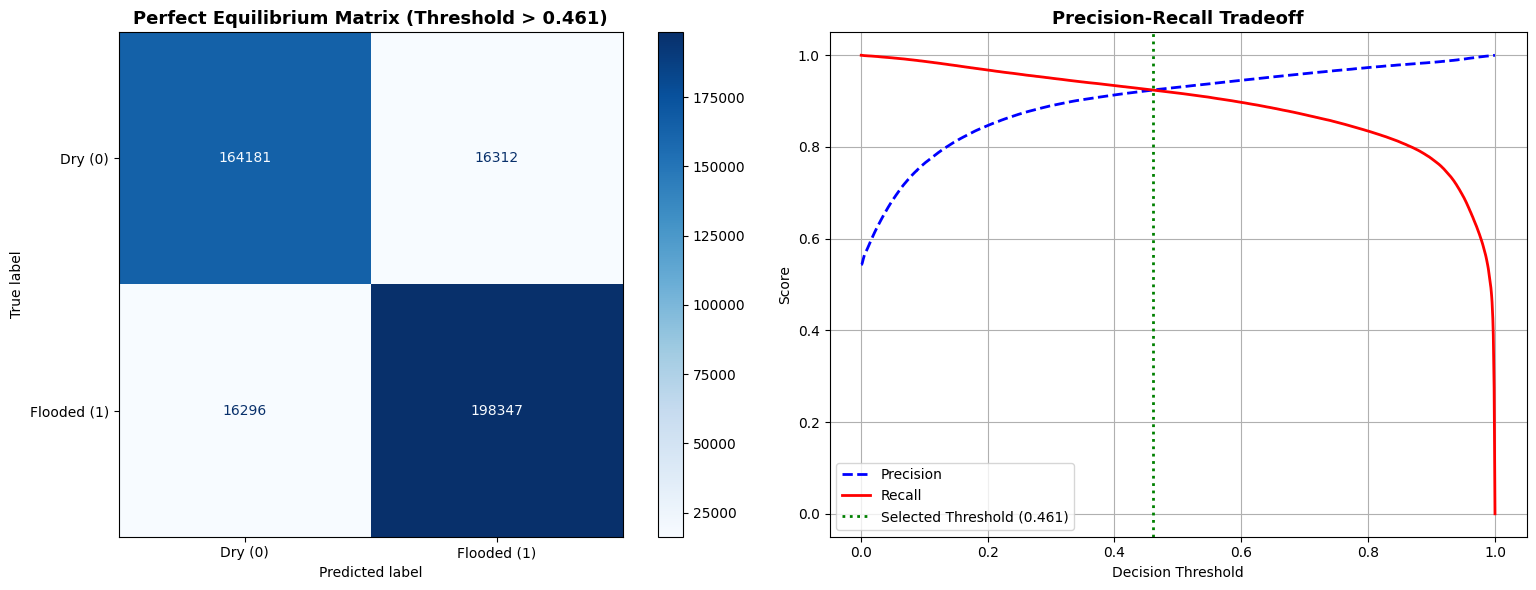

In [9]:
y_probs = optimized_xgb.predict_proba(X_test)[:, 1]
from sklearn.metrics import precision_recall_curve, precision_score, recall_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Use 500 thresholds for finer-grained search
thresholds_to_test = np.linspace(0.001, 0.999, 500)
results = []


for th in thresholds_to_test:
    preds = (y_probs >= th).astype(int)
    rec = recall_score(y_test, preds, zero_division=0)
    prec = precision_score(y_test, preds, zero_division=0)
    cm = confusion_matrix(y_test, preds)
    tn, fp, fn, tp = cm.ravel()
    f1 = 2 * prec * rec / (prec + rec + 1e-10)
    results.append({'threshold': th, 'precision': prec, 'recall': rec, 'f1': f1, 'fp': fp, 'fn': fn, 'tp': tp, 'tn': tn})

results_df = pd.DataFrame(results)

# ---- Strategy 1: Best F1 Score ----
best_f1_row = results_df.loc[results_df['f1'].idxmax()]
production_threshold = best_f1_row['threshold']

# ---- Strategy 2: 85% Recall Safety Target ----
safe_results = results_df[results_df['recall'] >= 0.85]
if not safe_results.empty:
    recall_85_row = safe_results.loc[safe_results['precision'].idxmax()]
else:
    recall_85_row = results_df.loc[results_df['recall'].idxmax()]

# ---- Strategy 3: PERFECT EQUILIBRIUM (Precision == Recall) ----
results_df['pr_diff'] = (results_df['precision'] - results_df['recall']).abs()
equilibrium_row = results_df.loc[results_df['pr_diff'].idxmin()]

print("=" * 60)
print(f"📊 STRATEGY 1: Best F1 Score")
print(f"   Threshold: {best_f1_row['threshold']:.3f}")
print(f"   Precision: {best_f1_row['precision']:.4f} | Recall: {best_f1_row['recall']:.4f} | F1: {best_f1_row['f1']:.4f}")
print(f"   TP: {int(best_f1_row['tp'])} | FP: {int(best_f1_row['fp'])} | FN: {int(best_f1_row['fn'])}")
print()
print(f"📊 STRATEGY 2: 85% Recall Safety Target")
print(f"   Threshold: {recall_85_row['threshold']:.3f}")
print(f"   Precision: {recall_85_row['precision']:.4f} | Recall: {recall_85_row['recall']:.4f} | F1: {recall_85_row['f1']:.4f}")
print(f"   TP: {int(recall_85_row['tp'])} | FP: {int(recall_85_row['fp'])} | FN: {int(recall_85_row['fn'])}")
print()
print(f"📊 STRATEGY 3: PERFECT EQUILIBRIUM (Precision ≈ Recall)")
print(f"   Threshold: {equilibrium_row['threshold']:.3f}")
print(f"   Precision: {equilibrium_row['precision']:.4f} | Recall: {equilibrium_row['recall']:.4f} | F1: {equilibrium_row['f1']:.4f}")
print(f"   TP: {int(equilibrium_row['tp'])} | FP: {int(equilibrium_row['fp'])} | FN: {int(equilibrium_row['fn'])}")
print("=" * 60)

# We use EQUILIBRIUM as the production threshold to get the perfectly balanced matrix!
production_threshold = equilibrium_row['threshold']
y_pred_prod = (y_probs >= production_threshold).astype(int)
cm_prod = confusion_matrix(y_test, y_pred_prod)

print("\n--- 📋 CLASSIFICATION REPORT (Equilibrium) ---")
print(classification_report(y_test, y_pred_prod, target_names=['Dry (0)', 'Flooded (1)']))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: Confusion Matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm_prod, display_labels=['Dry (0)', 'Flooded (1)'])
disp.plot(cmap='Blues', values_format='d', ax=axes[0])
axes[0].set_title(f"Perfect Equilibrium Matrix (Threshold > {production_threshold:.3f})", fontsize=13, fontweight='bold')
axes[0].grid(False)

# Right: PR Curve
precisions_curve, recalls_curve, thresholds_curve = precision_recall_curve(y_test, y_probs)
axes[1].plot(thresholds_curve, precisions_curve[:-1], 'b--', label='Precision', lw=2)
axes[1].plot(thresholds_curve, recalls_curve[:-1], 'r-', label='Recall', lw=2)
axes[1].axvline(x=production_threshold, color='green', linestyle=':', lw=2, label=f'Selected Threshold ({production_threshold:.3f})')
axes[1].set_xlabel('Decision Threshold')
axes[1].set_ylabel('Score')
axes[1].set_title('Precision-Recall Tradeoff', fontsize=13, fontweight='bold')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()



🔍 Feature Importance...


/tmp/ipykernel_5940/1748457941.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances[indices][:num_features], y=X_train.columns[indices][:num_features], palette='viridis')


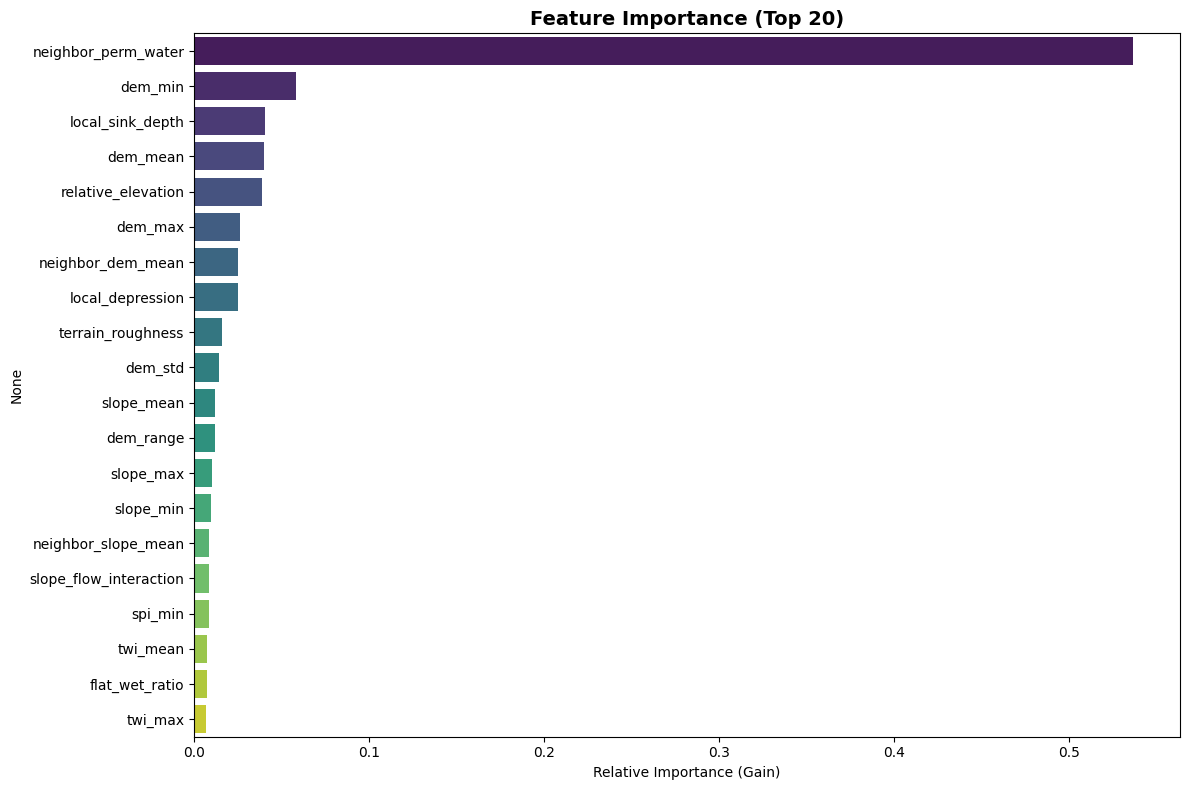

In [10]:
print("🔍 Feature Importance...")
importances = optimized_xgb.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(12, 8))
num_features = min(20, len(importances))
import seaborn as sns
sns.barplot(x=importances[indices][:num_features], y=X_train.columns[indices][:num_features], palette='viridis')
plt.title('Feature Importance (Top 20)', fontweight='bold', fontsize=14)
plt.xlabel('Relative Importance (Gain)')
plt.tight_layout()
plt.show()

